# Chicago Flock, Speed, and Red-light Camera Locations

This notebook plots the locations of mapped Flock ALPR cameras alongside Chicago speed and red-light cameras. For speed and red-light cameras, the notebook reduces then unique coordiate locations before plooting to avoid duplicates.

Run the cells from top to bottom.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

DATA_FOLDER = Path("../Data")

#### Finding The Number of ALPR camera

This code reads the `flock.geojson` file, which contains geographic information about camera locations, and extracts all features that represent individual points (potential camera locations).

For each point:
- It retrieves its latitude, longitude, manufacturer, operator, and other identifying information.
- It then checks whether the manufacturer, brand, model, or description contains the word "Flock" to determine whether the camera is explicitly identified as a Flock camera.
- It filters the locations to include only those within the defined Chicago geographic boundaries.
- Finally, it separates the locations into two groups: cameras explicitly identified as Flock and other ALPR cameras that are either from different manufacturers or are not clearly identified.


In [2]:
with open(DATA_FOLDER / "flock.geojson", encoding="utf-8") as file:
    geojson = json.load(file)

flock_rows = []
for feature in geojson.get("features", []):
    geometry = feature.get("geometry") or {}
    properties = feature.get("properties") or {}

    if geometry.get("type") != "Point":
        continue
    longitude, latitude = geometry["coordinates"][:2]

    searchable_tags = [
        properties.get("manufacturer", ""),
        properties.get("brand", ""),
        properties.get("model", ""),
        properties.get("description", ""),
    ]
    explicitly_flock = any(
        isinstance(value, str) and "flock" in value.lower()
        for value in searchable_tags
    )

    flock_rows.append({
        "id": feature.get("id", properties.get("@id", "")),
        "latitude": latitude,
        "longitude": longitude,
        "manufacturer": properties.get("manufacturer", "Unknown"),
        "operator": properties.get("operator", "Unknown"),
        "explicitly_flock": explicitly_flock,
    })

alpr = pd.DataFrame(flock_rows)

alpr = alpr[
    alpr["latitude"].between(41.60, 42.10)
    & alpr["longitude"].between(-87.95, -87.50)
].copy()

flock_osm = alpr[alpr["explicitly_flock"]].copy()
other_alpr = alpr[~alpr["explicitly_flock"]].copy()

print("ALPR points in the Chicago area:", len(alpr))
print("Explicitly Flock-tagged points:", len(flock_osm))
print("Other or untagged ALPR points:", len(other_alpr))


ALPR points in the Chicago area: 787
Explicitly Flock-tagged points: 99
Other or untagged ALPR points: 688


#### Finding The Number of Unique Speed and Red-Light Camera Locations

This code reads the Speed Camera Violations and Red Light Camera Violations CSV files, extracting only their latitude and longitude columns.

The code block essentialy does the following:
- It converts these coordinates into numeric values and treats any invalid entries as missing.
- It defines a function called unique_chicago_locations() that removes rows with missing coordinates, filters out locations outside the defined Chicago geographic boundaries, and rounds the coordinates to five decimal places to help identify duplicate locations.
- It then removes duplicate coordinates so that each camera location is counted only once.
- Finally, it applies this function to both datasets and prints the number of unique camera locations found.




In [3]:
speed = pd.read_csv(
    DATA_FOLDER / "Speed_Camera_Violations.csv",
    usecols=["LATITUDE", "LONGITUDE"],
)
red_light = pd.read_csv(
    DATA_FOLDER / "Red_Light_Camera_Violations.csv",
    usecols=["LATITUDE", "LONGITUDE"],
)

for camera_data in [speed, red_light]:
    camera_data["LATITUDE"] = pd.to_numeric(camera_data["LATITUDE"], errors="coerce")
    camera_data["LONGITUDE"] = pd.to_numeric(camera_data["LONGITUDE"], errors="coerce")

def unique_chicago_locations(data):
    data = data.dropna(subset=["LATITUDE", "LONGITUDE"]).copy()
    data = data[
        data["LATITUDE"].between(41.60, 42.10)
        & data["LONGITUDE"].between(-87.95, -87.50)
    ]
    data["latitude"] = data["LATITUDE"].round(5)
    data["longitude"] = data["LONGITUDE"].round(5)
    return data[["latitude", "longitude"]].drop_duplicates()

speed_locations = unique_chicago_locations(speed)
red_light_locations = unique_chicago_locations(red_light)

print("Unique speed-camera locations:", len(speed_locations))
print("Unique red-light-camera locations with coordinates:", len(red_light_locations))


Unique speed-camera locations: 236
Unique red-light-camera locations with coordinates: 603


#### Graph: Flock and Traffic Camera Locations in Chicago

Each marker represents a mapped location, not an individual violation. The gray points are ALPR cameras that are not explicitly tagged as Flock; they are context only. A point may overlap another marker, especially where cameras are close together.



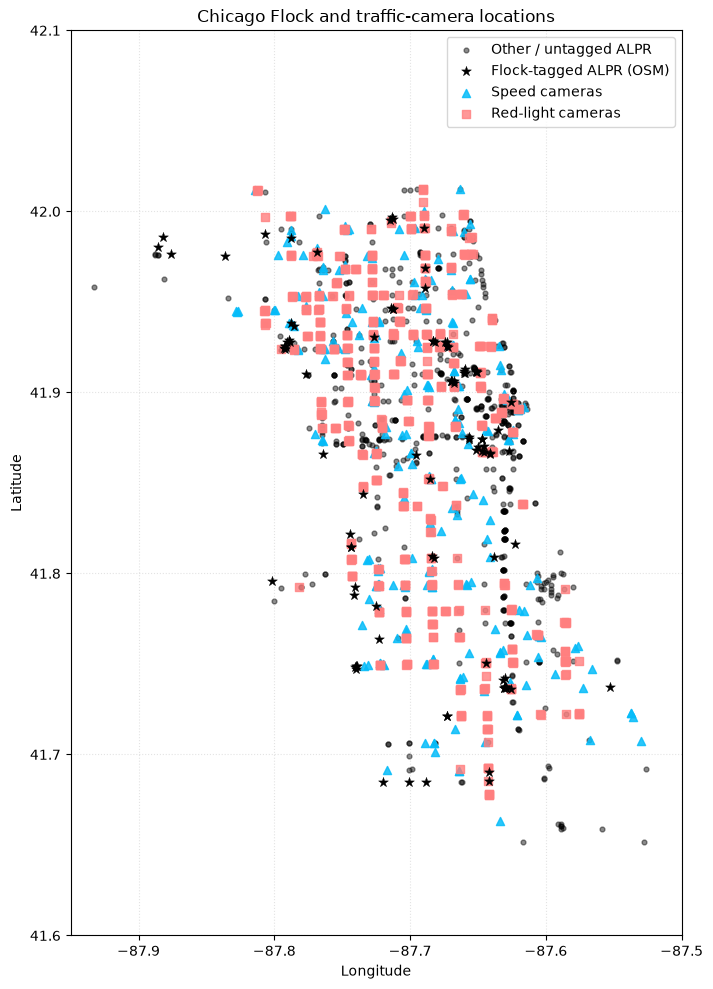

In [4]:
fig, ax = plt.subplots(figsize=(11, 10))

ax.scatter(
    other_alpr["longitude"], other_alpr["latitude"],
    s=12, color="black", alpha=0.45,
    label="Other / untagged ALPR", zorder=1,
)
ax.scatter(
    flock_osm["longitude"], flock_osm["latitude"],
    s=55, marker="*", color="black", edgecolors="black", linewidths=0.3,
    label="Flock-tagged ALPR (OSM)", zorder=4,
)
ax.scatter(
    speed_locations["longitude"], speed_locations["latitude"],
    s=34, marker="^", color="#06BCF9", alpha=0.85,
    label="Speed cameras", zorder=2,
)
ax.scatter(
    red_light_locations["longitude"], red_light_locations["latitude"],
    s=30, marker="s", color="#FF7F7F", alpha=0.8,
    label="Red-light cameras", zorder=3,
)

ax.set_title("Chicago Flock and traffic-camera locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-87.95, -87.50)
ax.set_ylim(41.60, 42.10)
ax.set_aspect(1 / 0.75)
ax.grid(True, linestyle=":", alpha=0.35)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


#### Graph 1 Observations

This graph shows us the geographic distribution of flock-tagged ALPR cameras, speed cameras, red-light cameras, and other ALPR cameras throughout Chicago. There are three main observations that we can take away from this:
1. Flock-tagged ALPR cameras seem to concentrated in the mid-upper right section of the graph.
2. Different camera types sometime overlap geograhpically.
3. Flock-tagged ALPR cameras appear less numerous.



#### Approx Distance to Nearest Traffic Camera

The following code block calculates the distance from each Flock camera location to its nearest speed camera and nearest red-light camera. It uses NumPy to calculate the north-south and east-west distances between the points, then finds the shortest distance for each Flock location. A boxplot is created to help visualize and compare how far Flock cameras are from speed cameras versus red-light cameras. 


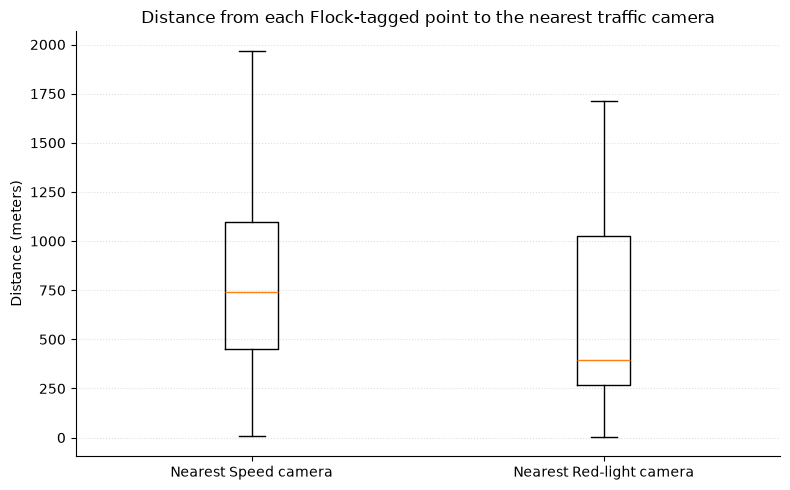

Median distance to a speed camera (m): 739.0
Median distance to a red-light camera (m): 396.6


In [11]:
import numpy as np

def nearest_distance_meters(source_points, target_points):
    source_lat = np.radians(source_points["latitude"].to_numpy())[:, None]
    source_lon = source_points["longitude"].to_numpy()[:, None]
    target_lat = target_points["latitude"].to_numpy()[None, :]
    target_lon = target_points["longitude"].to_numpy()[None, :]

    average_lat = (source_lat + np.radians(target_lat)) / 2
    north_south = (source_lat - np.radians(target_lat)) * 6_371_000
    east_west = np.radians(source_lon - target_lon) * 6_371_000 * np.cos(average_lat)
    distances = np.sqrt(north_south**2 + east_west**2)
    return distances.min(axis=1)

if len(flock_osm) and len(speed_locations) and len(red_light_locations):
    distance_data = pd.DataFrame({
        "Nearest speed camera": nearest_distance_meters(flock_osm, speed_locations),
        "Nearest red-light camera": nearest_distance_meters(flock_osm, red_light_locations),
    })

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot(
        [distance_data["Nearest speed camera"], distance_data["Nearest red-light camera"]],
        tick_labels=["Nearest Speed camera", "Nearest Red-light camera"],
        showfliers=False,
    )
    ax.set_title("Distance from each Flock-tagged point to the nearest traffic camera")
    ax.set_ylabel("Distance (meters)")
    ax.grid(axis="y", linestyle=":", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    print("Median distance to a speed camera (m):", round(distance_data["Nearest speed camera"].median(), 1))
    print("Median distance to a red-light camera (m):", round(distance_data["Nearest red-light camera"].median(), 1))


#### Graph 2 Obervations

This boxplot shows that Flock-tagged locations are generally closer to red-light cameras than speed cameras. The median distance to the nearest speed camera (left box) is approximately 739 meters, compared to 396.6 meters for red-light cameras (right box). This means Flock-tagged locations are typically about 342 meters closer to red-light cameras.

However, both boxplots show considerable variation in distance, meaning some Flock locations are much closer to traffic cameras than others. Overall, the graph suggests that Flock cameras tend to be located closer to red-light cameras than speed cameras.
